CAF Analysis Script
===========================
Author: Zae Moore (Syracuse University)
Last modified: 12-Dec-2025

Description:
This script analyzes MiniRun 6 flat CAF files

Purity = Number of True CC1mu2p0pi Events that pass all cuts/Number of events that pass all cuts <br>
Efficiency = Number of true signal events that pass all cuts/Number of true signal events <br> <br>

Signal means the reconstructed event is the "signal" we are looking for (reco passes the cuts) <br>
True means the truth level event is what we are looking for (truth passes the cuts) <br>
True Signal means the reconstructed event and truth level event pass the cuts <br> <br>

On nersc: Run with myenv (Python 3.12.5)

## Packages (run first to save time when running full script)

In [37]:
import uproot
import pandas as pd
import numpy as np
import awkward as ak
import matplotlib
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import os
import math
import csv
import math
import seaborn as sns
import sympy as smp
import sympy.stats
from scipy import stats,signal,ndimage,special,fft
from scipy.optimize import curve_fit
from scipy.integrate import quad
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as mpatches
from matplotlib import colors
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

plt.style.use('/global/homes/z/zaemoore/dune.mplstyle')

## Cut Definitions and Functions

In [38]:
def truth_cuts(pdg, p, mode):
    """
    Truth level cuts
    Checks that the truth event is a CC2p0pi1mu event
    """
    nprotons = np.count_nonzero(pdg == 2212)
    nmuons = np.count_nonzero(pdg == 13) + np.count_nonzero(pdg == -13)
    npions = np.count_nonzero(pdg == 111) + np.count_nonzero(pdg == 211) + np.count_nonzero(pdg == -211) 

    #CC1mu2p
    if nprotons == 2 and nmuons == 1 and npions == 0:
        return 1
    else:
        return 0
    
def reco_cuts(pdg, p, x_end, y_end, z_end, minerva_track_end_z):
    """
    Reco level cuts
    Cuts at the reco level
    - Counts 2 protons, 1 muon, and 0 pions
    - Cuts on proton momentum > 0.3 GeV/c
    - Requires proton to be contained in the TPC
    - Cuts on muon momentum > 0.3 GeV/c
    - Requires muon to punch out the back of minerva
    """
    nprotons = 0
    nmuons = 0
    npions = 0
    
    for part in range(len(pdg)):
        if pdg[part] == 2212: #and p[part] > 0.3: 
            if is_contained(x_end[part], y_end[part], z_end[part]):
                nprotons += 1
        if pdg[part] == 13 or pdg[part] == -13:
            #if p[part] >= 0.3: #and minerva_track_end_z[part] > 62.0:
            if minerva_track_end_z[part] > 62.0:
                nmuons += 1
        if pdg[part] == 111 or pdg[part] == 211 or pdg[part] == -211:
            npions += 1

    if nprotons == 2 and nmuons == 1 and npions == 0: #and len(pdg) == 3:
        return 1
    else:
        return 0
    
def mag(x):
    return np.sqrt(sum(i ** 2 for i in x))

def is_contained(x, y, z):
    tpc_dist = 8.0 #distance from the tpc walls for containment cuts
    xbound = 63.931
    ybound = 62.076
    zbound = 64.3163

    cont = False

    if abs(x) < xbound - tpc_dist and abs(y) < ybound - tpc_dist and abs(z) < zbound - tpc_dist:
        cont = True

    return cont

def theta(track1, track2):
    cos = np.dot(track1, track2) / (mag(track1) * mag(track2))
    cos = np.clip(cos, -1, 1)
    #p_theta = np.arccos(cos)
    return cos

def vector_sum(track1, track2):
    return np.add(track1, track2)

## Open root file and save relevant information from branches <br>

NOTE: this file's CafTree is already structured one-entry-per-interaction. <br>
Branches like reco_pdg / true_p_mag / true_track_start_x are
std::vector<double> (or vector<int32_t>) holding the values for every
particle/track in that interaction. <br>
There's no need to reconstruct events from a flat, particle-level table via boolean masks on file_index &
event -- each tree entry is already one event.

In [ ]:
f = uproot.open("/global/homes/z/zaemoore/2x2_CAF/multip_analysis_m6.5.root")
tree = f["CafTree"]

# Only pull the branches actually used below (faster than loading all 76)
needed_branches = [
    "true_pdg", "true_p_x", "true_p_y", "true_p_z", "true_p_mag",
    "true_track_start_x", "true_track_start_y", "true_track_start_z",
    "true_track_end_x", "true_track_end_y", "true_track_end_z", "true_nproton",
    "reco_pdg", "reco_p_x", "reco_p_y", "reco_p_z", "reco_p_mag",
    "reco_track_end_x", "reco_track_end_y", "reco_track_end_z",
    "minerva_track_end_z",
    "mode", "genie_weights", "NormCCMEC", "MaCCRES", "MvCCRES", "CCResVariationResponse",
    "FSIReweight_hN", "FSIReweight_INCL", "FSIReweight_G4BC",
    "nu_momentum_x", "nu_momentum_y", "nu_momentum_z",
    "file_index", "event",
]

branches = tree.arrays(needed_branches, library="ak")

n_events = len(branches)
print (n_events)

2246


## Calculate total purity and efficiency <br>

In [40]:
# Per event information for data frame
event_number = []
true_pdg = []
true_pmag = []
true_px = []
true_py = []
true_pz = []
true_proton_rank = []
reco_pdg = []
reco_pmag = []
reco_px = []
reco_py = []
reco_pz = []
reco_proton_rank = []

# Arrays to save information on whether each event passes reco and true cuts,
# and the type of event it is
true_signal_event = []
true_event = []
signal_event = []
mode_event = []

# Reco momentum and proton angle information
# each index corresponds to an event
# if there are no protons/muons, the value is 0
leading_p_p = []
recoil_p_p = []
muon_p = []
theta_pp = []
candidate_files = []

# Reco and true proton momentum and neutrino energy
true_proton_p = []
reco_proton_p = []
true_muon_p = []
true_nu_momentum = []

# Proton true and reco momentum for 2D histogram
hist_proton_truep = []
hist_proton_recop = []

# PID information
true_pid = []
reco_pid = []

# Neutrino energy and momentum information
true_nu_energy = []
true_nu_momentum = []

# Genie weights
genweight_all = []


# Loop directly over entries -- each entry is already one interaction/event
for i in range(n_events):

    true_pdg_ev = branches["true_pdg"][i]
    reco_pdg_ev = branches["reco_pdg"][i]
    true_p_mag_ev = branches["true_p_mag"][i]
    reco_p_mag_ev = branches["reco_p_mag"][i]

    true_p_x_ev = branches["true_p_x"][i]
    true_p_y_ev = branches["true_p_y"][i]
    true_p_z_ev = branches["true_p_z"][i]
    reco_p_x_ev = branches["reco_p_x"][i]
    reco_p_y_ev = branches["reco_p_y"][i]
    reco_p_z_ev = branches["reco_p_z"][i]

    true_track_start_x_ev = branches["true_track_start_x"][i]
    true_track_start_y_ev = branches["true_track_start_y"][i]
    true_track_start_z_ev = branches["true_track_start_z"][i]
    true_track_end_x_ev = branches["true_track_end_x"][i]
    true_track_end_y_ev = branches["true_track_end_y"][i]
    true_track_end_z_ev = branches["true_track_end_z"][i]

    reco_track_end_x_ev = branches["reco_track_end_x"][i]
    reco_track_end_y_ev = branches["reco_track_end_y"][i]
    reco_track_end_z_ev = branches["reco_track_end_z"][i]
    minerva_track_end_z_ev = branches["minerva_track_end_z"][i]

    mode_ev = branches["mode"][i]
    file_idx = branches["file_index"][i]

    xp_track = []
    yp_track = []
    zp_track = []

    # Do the reco event and matching truth event pass the cuts?
    reco_passes = reco_cuts(
        reco_pdg_ev, reco_p_mag_ev,
        reco_track_end_x_ev, reco_track_end_y_ev, reco_track_end_z_ev,
        minerva_track_end_z_ev,
    )
    truth_passes = truth_cuts(true_pdg_ev, true_p_mag_ev, mode_ev)

    signal_event.append(reco_passes)
    true_event.append(truth_passes)
    mode_event.append(mode_ev)

    if reco_passes == 1 and truth_passes == 1:
        true_signal_event.append(1)
    else:
        true_signal_event.append(0)

    # Save proton and muon momentum information for plots
    proton_p_reco = reco_p_mag_ev[reco_pdg_ev == 2212]
    proton_p_truth = true_p_mag_ev[true_pdg_ev == 2212]
    muon_p_truth_ev = true_p_mag_ev[true_pdg_ev == 13]

    nu_momentum = mag((
        branches["nu_momentum_x"][i],
        branches["nu_momentum_y"][i],
        branches["nu_momentum_z"][i],
    ))

    # Loop through particles in this event
    # Save information on true and/or reco protons and muons for data frame
    for part in range(len(true_pdg_ev)):

        # If the particle is a true and/or reco proton or muon, save its information
        if true_pdg_ev[part] == 2212 or true_pdg_ev[part] == 13 or true_pdg_ev[part] == -13 \
            or reco_pdg_ev[part] == 2212 or reco_pdg_ev[part] == 13 or reco_pdg_ev[part] == -13:
            
            event_number.append(i)
            true_pdg.append(true_pdg_ev[part])
            reco_pdg.append(reco_pdg_ev[part])
            true_pmag.append(true_p_mag_ev[part])
            reco_pmag.append(reco_p_mag_ev[part])
            true_px.append(true_p_x_ev[part])
            true_py.append(true_p_y_ev[part])
            true_pz.append(true_p_z_ev[part])
            reco_px.append(reco_p_x_ev[part])
            reco_py.append(reco_p_y_ev[part])
            reco_pz.append(reco_p_z_ev[part])


        true_pid.append(true_pdg_ev[part])
        reco_pid.append(reco_pdg_ev[part])
        if true_pdg_ev[part] == 2212:
            xp_track.append(true_track_end_x_ev[part] - true_track_start_x_ev[part])
            yp_track.append(true_track_end_y_ev[part] - true_track_start_y_ev[part])
            zp_track.append(true_track_end_z_ev[part] - true_track_start_z_ev[part])
            if reco_pdg_ev[part] == 2212:
                # Save proton momentum info for 2D histogram only if the
                # particle is both true and reco proton
                hist_proton_truep.append(true_p_mag_ev[part])
                hist_proton_recop.append(reco_p_mag_ev[part])


    if len(zp_track) == 2:
        # Compare angles for every combination of truth protons in events
        # with >= 2 protons
        for a in range(len(zp_track) - 1):
            for b in range(a + 1, len(zp_track)):
                track1 = [xp_track[a], yp_track[a], zp_track[a]]
                track2 = [xp_track[b], yp_track[b], zp_track[b]]
                angle = theta(track1, track2)
                if angle <= -0.95:
                    candidate_files.append(file_idx)
                theta_pp.append(angle)
    else:
        theta_pp.append(2)

    reco_proton_p.extend(ak.to_list(proton_p_reco))
    true_proton_p.extend(ak.to_list(proton_p_truth))
    true_muon_p.extend(ak.to_list(muon_p_truth_ev))

    # Find max (lead) and min (recoil) protons
    # Some events may be true CC2p1mu0pi, but the reconstruction may not see
    # any protons -- account for events with no proton momentum
    if len(proton_p_truth) == 0:
        leading_p_p.append(0)
        recoil_p_p.append(0)
    else:
        leading_p_p.append(max(proton_p_truth))
        recoil_p_p.append(min(proton_p_truth))

    if len(muon_p_truth_ev) == 0:
        muon_p.append(0)
    else:
        muon_p.append(muon_p_truth_ev[0])

    true_nu_momentum.append(nu_momentum)  

# Make the data frame with the information saved above
df = pd.DataFrame({
    "event_number": event_number,
    "true_pdg": true_pdg,
    "true_pmag": true_pmag,
    "true_px": true_px,
    "true_py": true_py,
    "true_pz": true_pz,
    "reco_pdg": reco_pdg,
    "reco_pmag": reco_pmag,
    "reco_px": reco_px,
    "reco_py": reco_py,
    "reco_pz": reco_pz,
})

# --- True proton rank (1 = highest momentum in that event) ---
df["true_proton_rank"] = np.nan
mask = df["true_pdg"] == 2212

sub = df.loc[mask].sort_values(["event_number", "true_pmag"], ascending=[True, False])
sub["true_proton_rank"] = sub.groupby("event_number").cumcount() + 1
df.loc[sub.index, "true_proton_rank"] = sub["true_proton_rank"]

# --- Reco proton rank (1 = highest momentum in that event) ---
df["reco_proton_rank"] = np.nan
mask_reco = df["reco_pdg"] == 2212

sub_reco = df.loc[mask_reco].sort_values(["event_number", "reco_pmag"], ascending=[True, False])
sub_reco["reco_proton_rank"] = sub_reco.groupby("event_number").cumcount() + 1
df.loc[sub_reco.index, "reco_proton_rank"] = sub_reco["reco_proton_rank"]

# In this code, signal means event that passes the reco cuts - passes cuts according to detector
# True signal event means an event that passes the reco cuts and true cuts
# True event passes the true cuts - passes cuts according to truth information
num_true_signal = sum(true_signal_event)   # Number of multiproton events that pass the cut
num_background = sum(signal_event) - num_true_signal  # Number of background events that pass the cut

print("Number of signal events", num_true_signal)
print("Number of background events", num_background)

purity = sum(true_signal_event) / sum(signal_event)
print("Purity measurement: ", purity)

efficiency = sum(true_signal_event) / sum(true_event)
print("Efficiency measurement: ", efficiency)

#print first few rows of the dataframe to check that it looks correct
#print(df[["event_number", "true_pdg", "true_pmag", "true_proton_rank", "reco_pdg", "reco_pmag", "reco_proton_rank"]].head(20))


/global/homes/z/zaemoore/.conda/envs/myenv/lib/python3.12/site-packages/awkward/_nplikes/array_module.py:313: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  result.shape = shape


Number of signal events 138
Number of background events 130
Purity measurement:  0.5149253731343284
Efficiency measurement:  0.5307692307692308


## Purity and efficiency vs. kinematic variables

/tmp/ipykernel_1996457/2747985058.py:87: RuntimeWarning: divide by zero encountered in scalar divide
  stat_error_lpp.append(1/np.sqrt(n_events))
/tmp/ipykernel_1996457/2747985058.py:110: RuntimeWarning: divide by zero encountered in scalar divide
  stat_error_rpp.append(1/np.sqrt(n_events))
/tmp/ipykernel_1996457/2747985058.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  stat_error_mu.append(1/np.sqrt(n_events))


"\n#Plot purity and efficiency vs. angle between protons\nax[2].errorbar(bin_centers_theta, purity_vals_theta, xerr=0.05, yerr=stat_error_theta, fmt='.', label='Purity', elinewidth=2, capsize=3)\nax[2].errorbar(bin_centers_theta, eff_vals_theta, xerr=0.05, yerr=stat_error_theta, fmt='.', label='Efficiency', elinewidth=2, capsize=3)\n#xerr=bin_width_theta/2 yerr=stat_error_theta\nax[2].set_xlabel('Angle between Protons')\nax[2].set_ylabel('Purity or Efficiency %')\nax[2].set_title('Purity and Efficiency vs. Angle between Protons', fontsize=14)\nax[2].set_xlim(-1, 1)\nax[2].grid(color='0.95')\nax[2].legend(loc='upper right')\n"

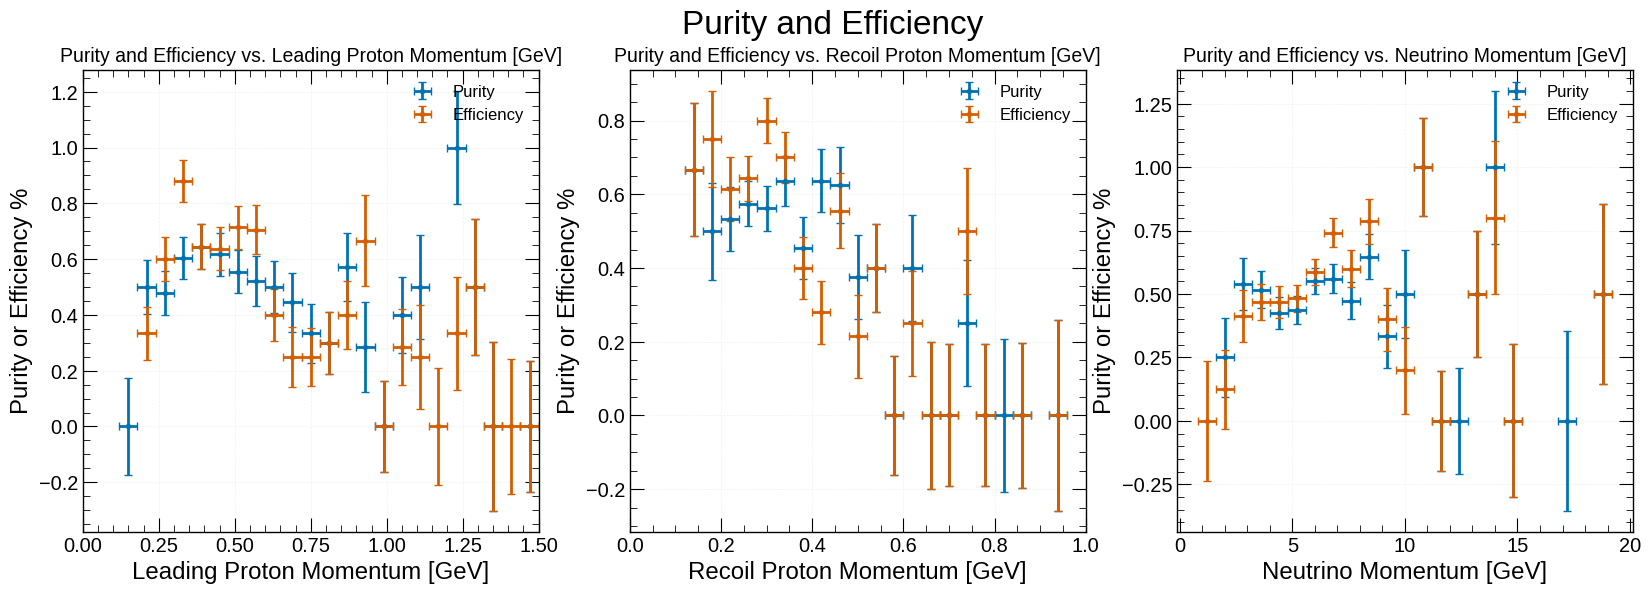

In [41]:
data = {'signal': signal_event, 'true': true_event, 'true and signal': true_signal_event, 'leading proton p': leading_p_p, 'recoil proton p': recoil_p_p, 'muon p': muon_p, 'nu momentum': true_nu_momentum, 'theta pp': theta_pp}
dfp = pd.DataFrame(data=data)
# All the independent variables are truth rn (momentum, angle)

#Save purity and efficiency values
purity_vals_lpp = []
purity_vals_rpp = []
purity_vals_mu = []
purity_vals_nu = []
purity_vals_theta = []
eff_vals_lpp = []
eff_vals_rpp = []
eff_vals_mu = []
eff_vals_nu = []
eff_vals_theta = []
stat_error_lpp = []
stat_error_rpp = []
stat_error_mu = []
stat_error_nu = []
stat_error_theta = []

#For significance plot
signal_lpp = []
signal_rpp = []
signal_mu = []
signal_nu = []
signal_theta = []
background_lpp = []
background_rpp = []
background_mu = []
background_nu = []
background_theta = []

#Leading proton momentum binning
nbins_lpp = 25
hist_lpp, bin_edges_lpp = np.histogram(leading_p_p, bins=nbins_lpp, range=(0,1.5)) #Create bins based on leading proton momentum
bin_centers_lpp = (bin_edges_lpp[:-1] + bin_edges_lpp[1:])/2
bin_width_lpp = (bin_edges_lpp[-1] + bin_edges_lpp[0])/nbins_lpp
labels_lpp = np.arange(0, nbins_lpp) #Label each bin numerically for leading proton momentum

dfp['bin lpp'] = pd.cut(dfp['leading proton p'], bins=bin_edges_lpp, labels=labels_lpp) #Create a column in df defining the number bin each event is in based on leading proton momentum

#Recoil proton momentum binning
nbins_rpp = 25
hist_rpp, bin_edges_rpp = np.histogram(recoil_p_p, bins=nbins_rpp, range=(0,1.0)) #Create bins based on recoil proton momentum
bin_centers_rpp = (bin_edges_rpp[:-1] + bin_edges_rpp[1:])/2
bin_width_rpp = (bin_edges_rpp[-1] + bin_edges_rpp[0])/nbins_rpp
labels_rpp = np.arange(0, nbins_rpp) #Label each bin numerically for recoil proton momentum

dfp['bin rpp'] = pd.cut(dfp['recoil proton p'], bins=bin_edges_rpp, labels=labels_rpp) #Create a column in df defining the number bin each event is in based on recoil proton momentum

#Muon momentum binning
nbins_mu = 25
hist_mu, bin_edges_mu = np.histogram(muon_p, bins=nbins_mu, range=(0,1.0)) #Create bins based on recoil proton momentum
bin_centers_mu = (bin_edges_mu[:-1] + bin_edges_mu[1:])/2
bin_width_mu = (bin_edges_mu[-1] + bin_edges_mu[0])/nbins_mu
labels_mu = np.arange(0, nbins_mu) #Label each bin numerically for recoil proton momentum

dfp['bin mu'] = pd.cut(dfp['muon p'], bins=bin_edges_mu, labels=labels_mu) #Create a column in df defining the number bin each event is in based on recoil proton momentum

#Neutrino energy binning
nbins_nu = 25
hist_nu, bin_edges_nu = np.histogram(true_nu_momentum, bins=nbins_nu, range=(0,20)) #Create bins based on true neutrino energy
bin_centers_nu = (bin_edges_nu[:-1] + bin_edges_nu[1:])/2
bin_width_nu = (bin_edges_nu[-1] + bin_edges_nu[0])/nbins_nu
labels_nu = np.arange(0, nbins_nu) #Label each bin numerically for true neutrino energy

dfp['bin nu'] = pd.cut(dfp['nu momentum'], bins=bin_edges_nu, labels=labels_nu) #Create a column in df defining the number bin each event is in based on true neutrino energy

#Theta pp binning
nbins_theta = 20
hist_theta, bin_edges_theta = np.histogram(theta_pp, bins=nbins_theta, range=(-1, 1)) #Create bins based on theta pp
bin_centers_theta = (bin_edges_theta[:-1] + bin_edges_theta[1:])/2
bin_width_theta = (bin_edges_theta[-1] + bin_edges_theta[0])/nbins_theta
labels_theta = np.arange(0, nbins_theta) #Label each bin numerically for theta pp

dfp['bin theta'] = pd.cut(dfp['theta pp'], bins=bin_edges_theta, labels=labels_theta) #Create a column in df defining the number bin each event is in based on theta pp

# Loop through each leading proton momentum bin and calculate purity & efficiency
for i in labels_lpp:
    df_bin = dfp[(dfp['bin lpp'] == i)]

    signal_bin = np.array(df_bin['signal'])
    true_signal_bin = np.array(df_bin['true and signal'])
    true_bin = np.array(df_bin['true'])
    n_events = len(signal_bin)
    stat_error_lpp.append(1/np.sqrt(n_events))

    signal_lpp.append(sum(signal_bin))
    background_lpp.append(sum(signal_bin) - sum(true_signal_bin))

    if sum(signal_bin) == 0:
        purity_vals_lpp.append(np.nan)
    else:
        purity_vals_lpp.append(sum(true_signal_bin)/sum(signal_bin))
    
    if sum(true_bin) == 0:
        eff_vals_lpp.append(np.nan)
    else:
        eff_vals_lpp.append(sum(true_signal_bin)/sum(true_bin))

# Loop through each recoil proton momentum bin and calculate purity & efficiency
for i in labels_rpp:
    df_bin = dfp[(dfp['bin rpp'] == i)]

    signal_bin = np.array(df_bin['signal'])
    true_signal_bin = np.array(df_bin['true and signal'])
    true_bin = np.array(df_bin['true'])
    n_events = len(signal_bin)
    stat_error_rpp.append(1/np.sqrt(n_events))

    signal_rpp.append(sum(signal_bin))
    background_rpp.append(sum(signal_bin) - sum(true_signal_bin))

    if sum(signal_bin) == 0:
        purity_vals_rpp.append(np.nan)
    else:
        purity_vals_rpp.append(sum(true_signal_bin)/sum(signal_bin))

    if sum(true_bin) == 0:
        eff_vals_rpp.append(np.nan)
    else:
        eff_vals_rpp.append(sum(true_signal_bin)/sum(true_bin))

# Loop through each muon momentum bin and calculate purity and efficiency
for i in labels_mu:
    df_bin = dfp[(dfp['bin mu'] == i)]

    signal_bin = np.array(df_bin['signal'])
    true_signal_bin = np.array(df_bin['true and signal'])
    true_bin = np.array(df_bin['true'])
    n_events = len(signal_bin)
    stat_error_mu.append(1/np.sqrt(n_events))

    signal_mu.append(sum(signal_bin))
    background_mu.append(sum(signal_bin) - sum(true_signal_bin))

    if sum(signal_bin) == 0:
        purity_vals_mu.append(np.nan)
    else:
        purity_vals_mu.append(sum(true_signal_bin)/sum(signal_bin))

    if sum(true_bin) == 0:
        eff_vals_mu.append(np.nan)
    else:
        eff_vals_mu.append(sum(true_signal_bin)/sum(true_bin))

# Loop through each true neutrino energy bin and calculate purity and efficiency
for i in labels_nu:
    df_bin = dfp[(dfp['bin nu'] == i)]

    signal_bin = np.array(df_bin['signal'])
    true_signal_bin = np.array(df_bin['true and signal'])
    true_bin = np.array(df_bin['true'])
    n_events = len(signal_bin)
    stat_error_nu.append(1/np.sqrt(n_events))

    signal_nu.append(sum(signal_bin))
    background_nu.append(sum(signal_bin) - sum(true_signal_bin))

    if sum(signal_bin) == 0:
        purity_vals_nu.append(np.nan)
    else:
        purity_vals_nu.append(sum(true_signal_bin)/sum(signal_bin))

    if sum(true_bin) == 0:
        eff_vals_nu.append(np.nan)
    else:
        eff_vals_nu.append(sum(true_signal_bin)/sum(true_bin))

# Loop through each angle between proton bin and calculate purity and efficiency FOR LATER
for i in labels_theta:
    df_bin = dfp[(dfp['bin theta'] == i)]

    signal_bin = np.array(df_bin['signal'])
    true_signal_bin = np.array(df_bin['true and signal'])
    true_bin = np.array(df_bin['true'])
    n_events = len(signal_bin)
    stat_error_theta.append(1/np.sqrt(n_events))

    signal_theta.append(sum(signal_bin))
    background_theta.append(sum(signal_bin) - sum(true_signal_bin))

    if sum(signal_bin) == 0:
        purity_vals_theta.append(np.nan)
    else:
        purity_vals_theta.append(sum(true_signal_bin)/sum(signal_bin))

    if sum(true_bin) == 0:
        eff_vals_theta.append(np.nan)
    else:
        eff_vals_theta.append(sum(true_signal_bin)/sum(true_bin))

# Delete the last bin value because we are plotting each step from the leftmost bin edge
lpp_values = np.delete(bin_edges_lpp, nbins_lpp)
rpp_values = np.delete(bin_edges_rpp, nbins_rpp)
mu_values = np.delete(bin_edges_mu, nbins_mu)
nu_values = np.delete(bin_edges_nu, nbins_nu)
theta_values = np.delete(bin_edges_theta, nbins_theta)


#Purity and Efficiency Plots
fig, ax = plt.subplots(1, 3, figsize=(20,6))
fig.suptitle('Purity and Efficiency', fontsize=24)
#Plot purity and efficiency vs. leading proton momentum
ax[0].errorbar(bin_centers_lpp, purity_vals_lpp, xerr=bin_width_lpp/2, yerr=stat_error_lpp, fmt='.', label='Purity', elinewidth=2, capsize=3)
ax[0].errorbar(bin_centers_lpp, eff_vals_lpp, xerr=bin_width_lpp/2, yerr=stat_error_lpp, fmt='.', label='Efficiency', elinewidth=2, capsize=3)
ax[0].set_xlabel('Leading Proton Momentum [GeV]')
ax[0].set_ylabel('Purity or Efficiency %')
ax[0].set_title('Purity and Efficiency vs. Leading Proton Momentum [GeV]', fontsize=14)
ax[0].set_xlim(0, 1.5)
ax[0].grid(color='0.95')
ax[0].legend(loc='upper right')
#Plot purity and efficiency vs. recoil proton momentum
ax[1].errorbar(bin_centers_rpp, purity_vals_rpp, xerr=bin_width_rpp/2, yerr=stat_error_rpp, fmt='.', label='Purity', elinewidth=2, capsize=3)
ax[1].errorbar(bin_centers_rpp, eff_vals_rpp, xerr=bin_width_rpp/2, yerr=stat_error_rpp, fmt='.', label='Efficiency', elinewidth=2, capsize=3)
ax[1].set_xlabel('Recoil Proton Momentum [GeV]')
ax[1].set_ylabel('Purity or Efficiency %')
ax[1].set_title('Purity and Efficiency vs. Recoil Proton Momentum [GeV]', fontsize=14)
ax[1].set_xlim(0, 1.0)
ax[1].grid(color='0.95')
ax[1].legend(loc='upper right')
#Plot purity and efficiency vs. neutrino energy
ax[2].errorbar(bin_centers_nu, purity_vals_nu, xerr=bin_width_nu/2, yerr=stat_error_nu, fmt='.', label='Purity', elinewidth=2, capsize=3)
ax[2].errorbar(bin_centers_nu, eff_vals_nu, xerr=bin_width_nu/2, yerr=stat_error_nu, fmt='.', label='Efficiency', elinewidth=2, capsize=3)
ax[2].set_xlabel('Neutrino Momentum [GeV]')
ax[2].set_ylabel('Purity or Efficiency %')
ax[2].set_title('Purity and Efficiency vs. Neutrino Momentum [GeV]', fontsize=14)
ax[2].grid(color='0.95')
ax[2].legend(loc='upper right')
"""
#Plot purity and efficiency vs. angle between protons
ax[2].errorbar(bin_centers_theta, purity_vals_theta, xerr=0.05, yerr=stat_error_theta, fmt='.', label='Purity', elinewidth=2, capsize=3)
ax[2].errorbar(bin_centers_theta, eff_vals_theta, xerr=0.05, yerr=stat_error_theta, fmt='.', label='Efficiency', elinewidth=2, capsize=3)
#xerr=bin_width_theta/2 yerr=stat_error_theta
ax[2].set_xlabel('Angle between Protons')
ax[2].set_ylabel('Purity or Efficiency %')
ax[2].set_title('Purity and Efficiency vs. Angle between Protons', fontsize=14)
ax[2].set_xlim(-1, 1)
ax[2].grid(color='0.95')
ax[2].legend(loc='upper right')
"""
#print(df)

#---------------------------------------------
#Use true and reco energy bins for purity and efficiency
#---------------------------------------------

## Neutrino Energy
Neutrino energy truth level acceptance range <br>
Use this to inform the energy range to integrate the flux over for cross section calculation

## Event Modes

Examine what the RES events are

Percentage of true signal events that are MEC:  0.2463768115942029


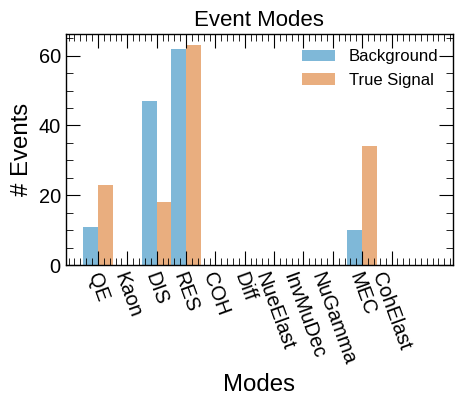

In [42]:
#Look at what type of events are background. Background = signal, not true
background_mode = []
true_signal_mode = []

for ev in range(len(mode_event)):
    if signal_event[ev] == 1 and true_event[ev] == 0:
        background_mode.append(mode_event[ev])
    elif signal_event[ev] == 1 and true_event[ev] == 1:
        true_signal_mode.append(mode_event[ev])

mec_perc = true_signal_mode.count(10)/len(true_signal_mode)
print("Percentage of true signal events that are MEC: ", mec_perc)

#Make a histogram of the background event modes
fig = plt.figure(figsize=(5,3))
n, bins, edges = plt.hist(background_mode, bins=np.arange(1.0, 13.0, 0.5), density=False, alpha=0.5, align='left')
n_ts, bins_ts, edges_ts = plt.hist(true_signal_mode, bins=np.arange(1.0, 13.0, 0.5), density=False, alpha=0.5, align='right')
plt.xticks(np.arange(1.25, 12.25, 1.0), ['QE', 'Kaon', 'DIS', 'RES', 'COH', 'Diff', 'NueElast', 'InvMuDec', 'NuGamma', 'MEC', 'CohElast'], rotation=290)
plt.xlabel("Modes")
plt.ylabel("# Events")
plt.title("Event Modes", fontsize=16)
plt.legend(['Background', 'True Signal'])
plt.show()

## Significance

/tmp/ipykernel_1996457/127612411.py:2: RuntimeWarning: invalid value encountered in divide
  sig_lpp = np.array(signal_lpp)/(np.sqrt(np.array(signal_lpp) + np.array(background_lpp)))
/tmp/ipykernel_1996457/127612411.py:3: RuntimeWarning: invalid value encountered in divide
  sig_rpp = np.array(signal_rpp)/(np.sqrt(np.array(signal_rpp) + np.array(background_rpp)))
/tmp/ipykernel_1996457/127612411.py:4: RuntimeWarning: invalid value encountered in divide
  sig_nu = np.array(signal_nu)/(np.sqrt(np.array(signal_nu) + np.array(background_nu)))


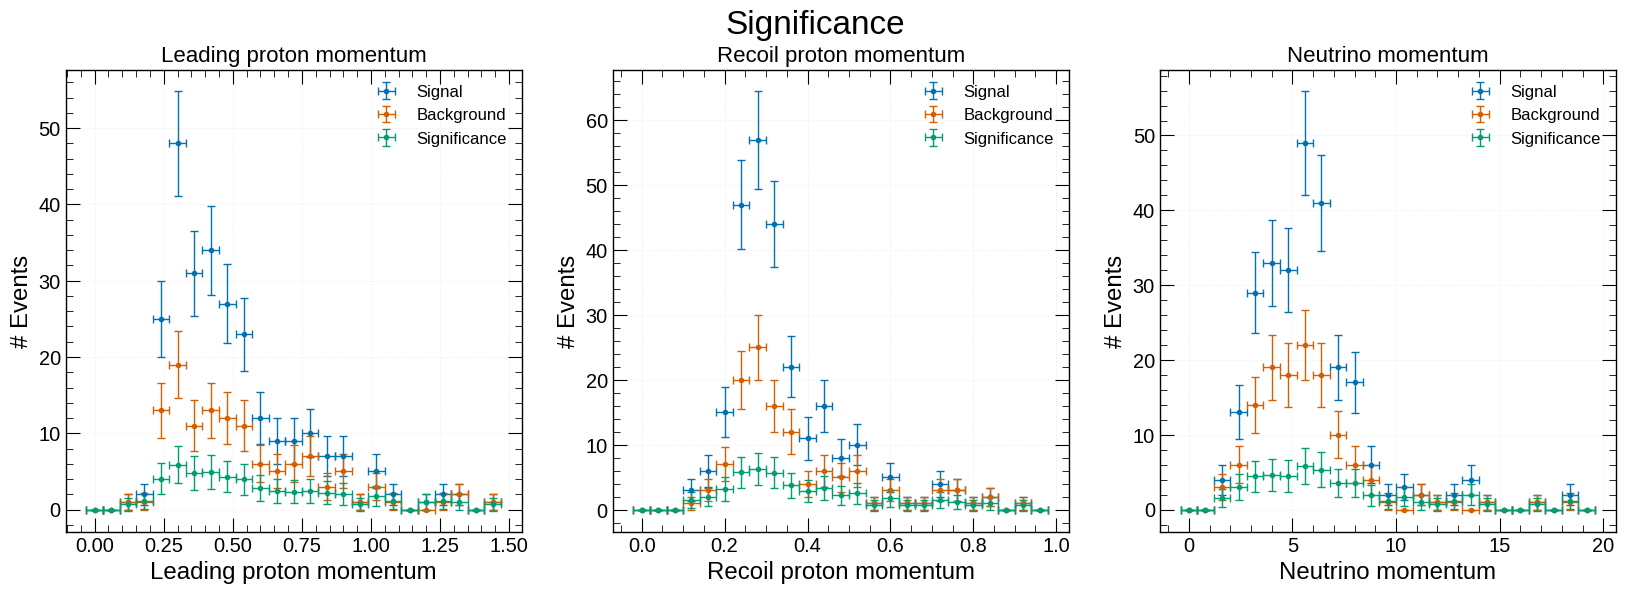

Leading proton momentum cutoff:  0.3
Recoil proton momentum cutoff:  0.28
Neutrino momentum cutoff:  5.6000000000000005


In [43]:
#Plot signal, background, and significance vs. proton momentum, muon momentum, and neutrino energy
sig_lpp = np.array(signal_lpp)/(np.sqrt(np.array(signal_lpp) + np.array(background_lpp)))
sig_rpp = np.array(signal_rpp)/(np.sqrt(np.array(signal_rpp) + np.array(background_rpp)))
sig_nu = np.array(signal_nu)/(np.sqrt(np.array(signal_nu) + np.array(background_nu)))

np.nan_to_num(sig_lpp, False, nan=0.0, posinf=0.0, neginf=0.0)
np.nan_to_num(sig_rpp, False, nan=0.0, posinf=0.0, neginf=0.0)
np.nan_to_num(sig_nu, False, nan=0.0, posinf=0.0, neginf=0.0)

fig, ax = plt.subplots(1, 3, figsize=(20,6))
fig.suptitle('Significance', fontsize=24)
#Leading Proton Momentum
ax[0].errorbar(lpp_values, signal_lpp, xerr=bin_width_lpp/2, yerr=(np.sqrt(signal_lpp)), fmt='.', label='Signal', elinewidth=1, capsize=3)
ax[0].errorbar(lpp_values, background_lpp, xerr=bin_width_lpp/2, yerr=(np.sqrt(background_lpp)), fmt='.', label='Background', elinewidth=1, capsize=3)
ax[0].errorbar(lpp_values, sig_lpp, xerr=bin_width_lpp/2, yerr=(np.sqrt(sig_lpp)), fmt='.', label='Significance', elinewidth=1, capsize=3)
ax[0].set_xlabel('Leading proton momentum')
ax[0].set_ylabel('# Events')
ax[0].set_title('Leading proton momentum', fontsize=16)
ax[0].legend()
ax[0].grid(color='0.95')
#Recoil Proton Momentum
ax[1].errorbar(rpp_values, signal_rpp, xerr=bin_width_rpp/2, yerr=(np.sqrt(signal_rpp)), fmt='.', label='Signal', elinewidth=1, capsize=3)
ax[1].errorbar(rpp_values, background_rpp, xerr=bin_width_rpp/2, yerr=(np.sqrt(background_rpp)), fmt='.', label='Background', elinewidth=1, capsize=3)
ax[1].errorbar(rpp_values, sig_rpp, xerr=bin_width_rpp/2, yerr=(np.sqrt(sig_rpp)), fmt='.', label='Significance', elinewidth=1, capsize=3)
ax[1].set_xlabel('Recoil proton momentum')
ax[1].set_ylabel('# Events')
ax[1].set_title('Recoil proton momentum', fontsize=16)
ax[1].legend()
ax[1].grid(color='0.95')
#Neutrino Momentum
ax[2].errorbar(nu_values, signal_nu, xerr=bin_width_nu/2, yerr=(np.sqrt(signal_nu)), fmt='.', label='Signal', elinewidth=1, capsize=3)
ax[2].errorbar(nu_values, background_nu, xerr=bin_width_nu/2, yerr=(np.sqrt(background_nu)), fmt='.', label='Background', elinewidth=1, capsize=3)
ax[2].errorbar(nu_values, sig_nu, xerr=bin_width_nu/2, yerr=(np.sqrt(sig_nu)), fmt='.', label='Significance', elinewidth=1, capsize=3)
ax[2].set_xlabel('Neutrino momentum')
ax[2].set_ylabel('# Events')
ax[2].set_title('Neutrino momentum', fontsize=16)
ax[2].legend()
ax[2].grid(color='0.95')

plt.show()

print("Leading proton momentum cutoff: ", lpp_values[np.nanargmax(sig_lpp)])
print("Recoil proton momentum cutoff: ", rpp_values[np.nanargmax(sig_rpp)])
print("Neutrino momentum cutoff: ", nu_values[np.nanargmax(sig_nu)])

## Proton Momentum truth vs. reco plots

<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1996457/853827270.py:26: SyntaxWarning: invalid escape sequence '\m'
  plt.suptitle("True vs. Reco Proton Momentum for CC 2p1$\mu$0$\pi$ Events", y=0.92, fontsize=16)


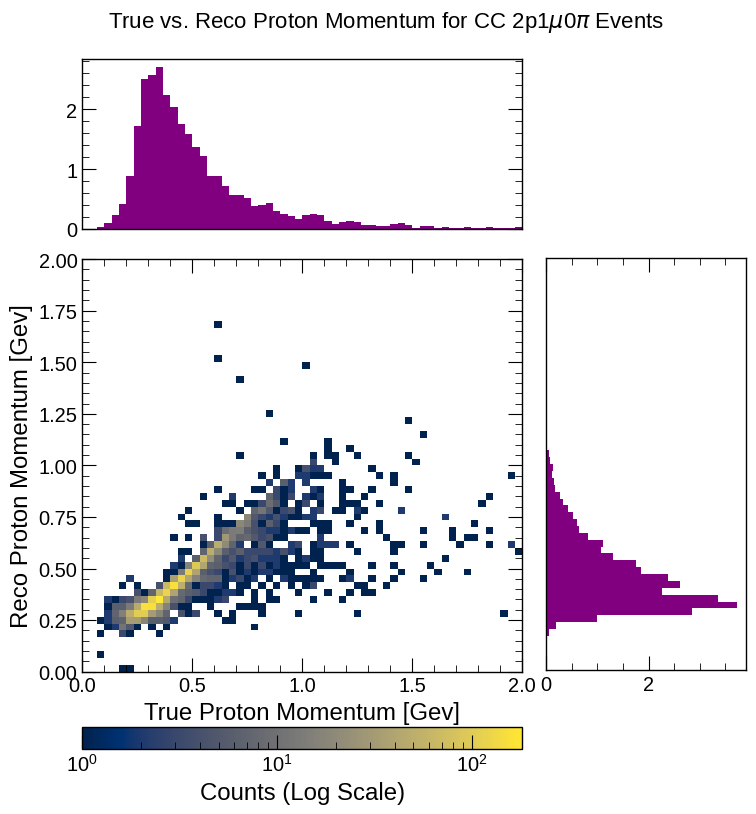

In [44]:
#2D histogram with 1D projections
fig = plt.figure(figsize=(8,10))
left, width, bottom, height = 0.12, 0.55, 0.12, 0.55
bottom_h = left_h = left + width + 0.03
#Dimensions
dim_2dhist = [left, bottom, width, height] #Dimensions of 2d hist
dim_1dhistx = [left, bottom_h, width, 0.17] #Dimensions of 1d x hist
dim_1dhisty = [left_h, bottom + 0.139, 0.25, height-0.138] #Dimensions of 1d y hist
#Make the plots
ax2dhist = plt.axes(dim_2dhist) #2d hist plot
ax1dhistx = plt.axes(dim_1dhistx) #1d x hist plot
ax1dhisty = plt.axes(dim_1dhisty) #1d y hist plot
#Plot histograms
_,_,_,im =ax2dhist.hist2d(hist_proton_truep, hist_proton_recop, bins=60, range=((0,2),(0,2)), norm=colors.LogNorm())
ax1dhistx.hist(true_proton_p, bins=60, range=(0,2), density=True, color='purple')
ax1dhisty.hist(reco_proton_p, bins=60, range=(0,2), density=True, orientation='horizontal', color='purple')
ax1dhistx.set_xlim(0,2)
ax1dhisty.set_ylim(0,2)
#Make it pretty
ax2dhist.set_xlabel("True Proton Momentum [Gev]")
ax2dhist.set_ylabel("Reco Proton Momentum [Gev]")
ax1dhistx.get_xaxis().set_visible(False)
ax1dhisty.get_yaxis().set_visible(False)
cbar = plt.colorbar(im, ax=ax2dhist, pad=0.1, location='bottom')
cbar.set_label('Counts (Log Scale)')
plt.suptitle("True vs. Reco Proton Momentum for CC 2p1$\mu$0$\pi$ Events", y=0.92, fontsize=16)
plt.show()


## Purity and Efficiency vs. Cuts 

Scatter plot showing the progression of the purity and efficiency as each subsequent cut is added

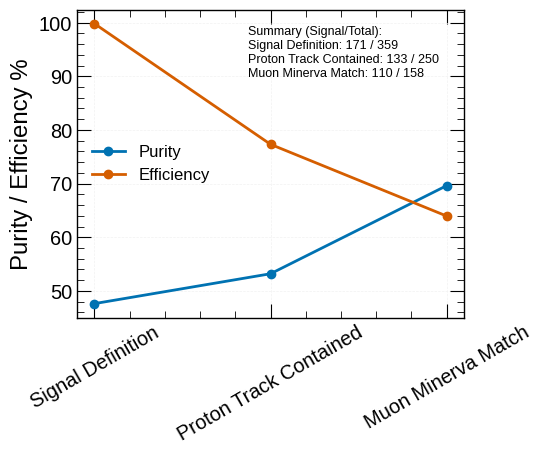

In [45]:
#Not using the cuts with momentum, those dropped the purity compared to the minerva matching
#Cut 1: vertex within volume, Np=2, Nmu=1, Npi=0
#Cut 2: Proton track fully contained
#Cut 3: Muon track punches out the back of minerva
purity_cuts = [47.63, 53.20, 69.62]
efficiency_cuts = [99.82, 77.32, 63.95]
phase = ['Signal Definition', 'Proton Track Contained', 'Muon Minerva Match']
phase_num = [1, 2, 3]

plt.figure(figsize=(5,4))
plt.plot(phase_num, purity_cuts, marker='o', label='Purity', linewidth=2)
plt.plot(phase_num, efficiency_cuts, marker='o', label='Efficiency', linewidth=2)
plt.xticks(phase_num, phase, rotation=30)
plt.ylabel('Purity / Efficiency %')
#plt.title('Purity and Efficiency of Cuts')
plt.grid(color='0.95')
plt.legend(loc='center left')
plt.text(1.87, 90, "Summary (Signal/Total): \nSignal Definition: 171 / 359 \nProton Track Contained: 133 / 250 \n" \
"Muon Minerva Match: 110 / 158", color='black', fontsize=9)
plt.show()

#171 signal events cut 1
#133 signal events cut 2
#110 signal events cut 3

## Angle between protons histogram

Histogram displaying the number of events for each bin of angle between proton momenta. Bins are 0.05 wide, plotting the cosine of the angle between the leading and recoil proton.

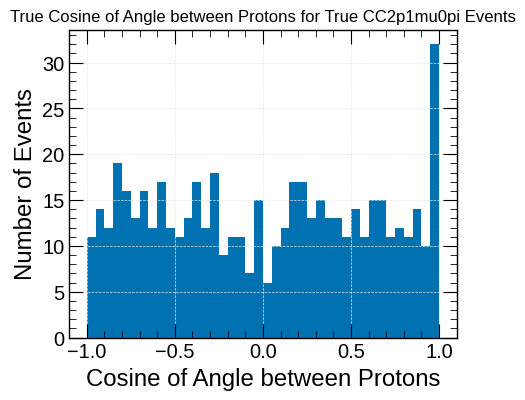

11


In [46]:
#theta_pp histogram
plt.figure(figsize=(5,4))
plt.hist(theta_pp, bins=40, range=(-1,1))
plt.xlabel('Cosine of Angle between Protons')
plt.ylabel('Number of Events')
plt.title('True Cosine of Angle between Protons for True CC2p1mu0pi Events', fontsize=12)
plt.grid(color='0.9')
#plt.legend(loc='upper right')
plt.show()

count = sum(1 for x in theta_pp if x <= -0.95)
print(count)

## Kinematics

Number of events with >=2 protons: 797


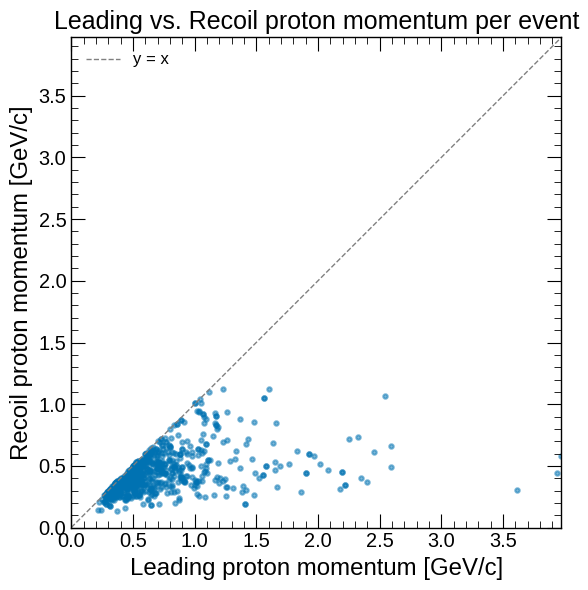

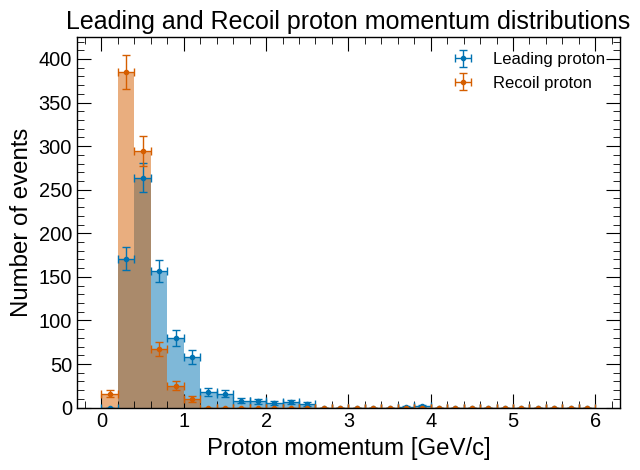

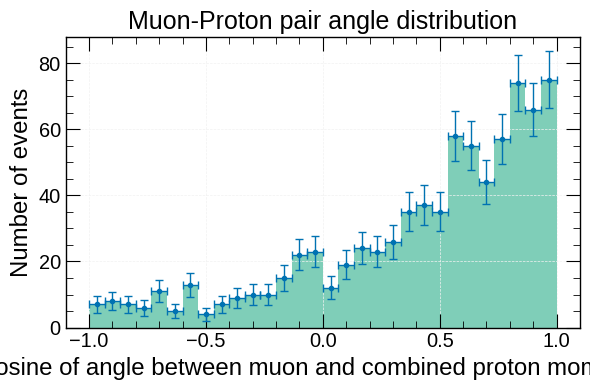

In [47]:
#---------------------------- Merge leading proton, recoil proton, and muon momentum dataframes ----------------------------
# Get rank 1 and rank 2 proton momenta per event, merged on event_number
# so we only keep events that have BOTH a rank 1 and rank 2 proton
rank1_true = df.loc[df["true_proton_rank"] == 1, ["event_number", "true_pmag", "true_px", "true_py", "true_pz"]]
rank2_true = df.loc[df["true_proton_rank"] == 2, ["event_number", "true_pmag", "true_px", "true_py", "true_pz"]]
muon_true = df.loc[abs(df["true_pdg"]) == 13, ["event_number", "true_pmag", "true_px", "true_py", "true_pz", "true_pdg"]]

muon_true = muon_true.rename(columns={
    "true_pmag": "true_pmag_muon",
    "true_px": "true_px_muon",
    "true_py": "true_py_muon",
    "true_pz": "true_pz_muon",
})

merged_true = pd.merge(rank1_true, rank2_true, on="event_number", suffixes=("_rank1", "_rank2"))
merged_true = pd.merge(merged_true, muon_true, on="event_number")

# Check
#print(merged_true.head(10))

print(f"Number of events with >=2 protons: {len(merged_true)}")

#---------------------------- Leading vs. recoil proton momenta ----------------------------
plt.figure(figsize=(6, 6))
plt.scatter(merged_true["true_pmag_rank1"], merged_true["true_pmag_rank2"], s=10, alpha=0.5)
plt.xlabel("Leading proton momentum [GeV/c]")
plt.ylabel("Recoil proton momentum [GeV/c]")
plt.title("Leading vs. Recoil proton momentum per event", fontsize=18)

# Optional: force equal aspect and draw the y=x line, since rank2 <= rank1 always
max_p = max(merged_true["true_pmag_rank1"].max(), merged_true["true_pmag_rank2"].max())
plt.plot([0, max_p], [0, max_p], color="gray", linestyle="--", linewidth=1, label="y = x")
plt.xlim(0, max_p)
plt.ylim(0, max_p)
plt.gca().set_aspect("equal")
plt.legend()
plt.tight_layout()
plt.show()

#---------------------------- Leading and recoil proton momenta separate histograms with stat errors ----------------------------
nbins_true_pmag = 30
hist_true_pmag, bin_edges_true_pmag = np.histogram(merged_true["true_pmag_rank1"], bins=nbins_true_pmag, range=(0, 6))
bin_centers_true_pmag = (bin_edges_true_pmag[:-1] + bin_edges_true_pmag[1:])/2
bin_width_true_pmag = (bin_edges_true_pmag[-1] + bin_edges_true_pmag[0])/nbins_true_pmag
labels_true_pmag = np.arange(0, nbins_true_pmag) 

hist_true_pmag_rank2, bin_edges_true_pmag_rank2 = np.histogram(merged_true["true_pmag_rank2"], bins=nbins_true_pmag, range=(0, 6))
bin_centers_true_pmag_rank2 = (bin_edges_true_pmag_rank2[:-1] + bin_edges_true_pmag_rank2[1:])/2
bin_width_true_pmag_rank2 = (bin_edges_true_pmag_rank2[-1] + bin_edges_true_pmag_rank2[0])/nbins_true_pmag

# Can do np.hist to get x and y values, then plot those as a step/scatter function with error bars
#plt.hist(merged_true["true_pmag_rank1"], bins=30, alpha=0.5, label="Leading proton")
#plt.hist(merged_true["true_pmag_rank2"], bins=30, alpha=0.5, label="Recoil proton")
plt.errorbar(bin_centers_true_pmag, hist_true_pmag, xerr=bin_width_true_pmag/2, yerr=np.sqrt(hist_true_pmag), fmt='.', label='Leading proton', elinewidth=1, capsize=3)
plt.errorbar(bin_centers_true_pmag_rank2, hist_true_pmag_rank2, xerr=bin_width_true_pmag_rank2/2, yerr=np.sqrt(hist_true_pmag_rank2), fmt='.', label='Recoil proton', elinewidth=1, capsize=3)
plt.stairs(hist_true_pmag, bin_edges_true_pmag, fill=True, color='#0072B2', alpha=0.5, edgecolor='black')
plt.stairs(hist_true_pmag_rank2, bin_edges_true_pmag_rank2, fill=True, color='#D55E00', alpha=0.5, edgecolor='black')
plt.xlabel("Proton momentum [GeV/c]")
plt.ylabel("Number of events")
plt.title("Leading and Recoil proton momentum distributions", fontsize=18)
plt.legend()
plt.tight_layout()
plt.show()

#---------------------------- Muon-Proton pair angle ----------------------------
muon_proton_angles = []

for index, row in merged_true.iterrows():
    proton1 = [row["true_px_rank1"], row["true_py_rank1"], row["true_pz_rank1"]]
    proton2 = [row["true_px_rank2"], row["true_py_rank2"], row["true_pz_rank2"]]
    muon = [row["true_px_muon"], row["true_py_muon"], row["true_pz_muon"]]

    combined_protons = vector_sum(proton1, proton2)
    angle = theta(combined_protons, muon)
    muon_proton_angles.append(angle)


nbins_muon_proton = 30
hist_muon_proton_true, bin_edges_muon_proton_true = np.histogram(muon_proton_angles, bins=nbins_muon_proton, range=(-1, 1))
bin_centers_muon_proton = (bin_edges_muon_proton_true[:-1] + bin_edges_muon_proton_true[1:])/2
bin_width_muon_proton = (bin_edges_muon_proton_true[-1] - bin_edges_muon_proton_true[0]) / nbins_muon_proton
labels_muon_proton = np.arange(0, nbins_muon_proton)

plt.figure(figsize=(6, 4))
plt.errorbar(bin_centers_muon_proton, hist_muon_proton_true, xerr=bin_width_muon_proton/2, yerr=np.sqrt(hist_muon_proton_true), fmt='.', label='Muon-Proton pair angle', elinewidth=1, capsize=3)
plt.stairs(hist_muon_proton_true, bin_edges_muon_proton_true, fill=True, color='#009E73', alpha=0.5, edgecolor='black')
plt.xlabel("Cosine of angle between muon and combined proton momentum")
plt.ylabel("Number of events")
plt.title("Muon-Proton pair angle distribution", fontsize=18)
plt.grid(color='0.95')
plt.tight_layout()
plt.show()


## Kinematics Reco

Number of events with >=2 protons: 1016


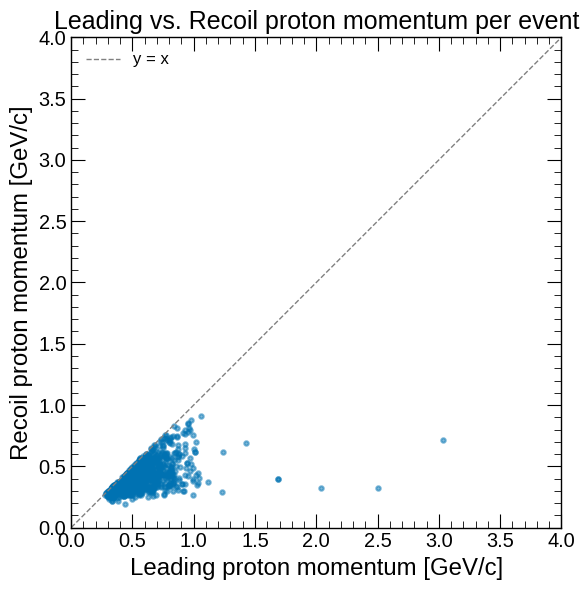

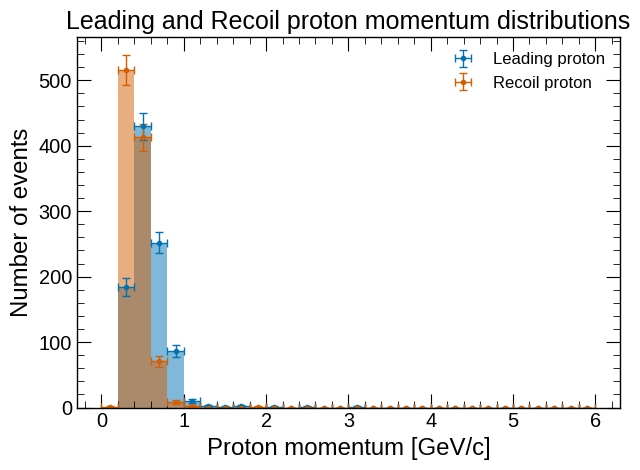

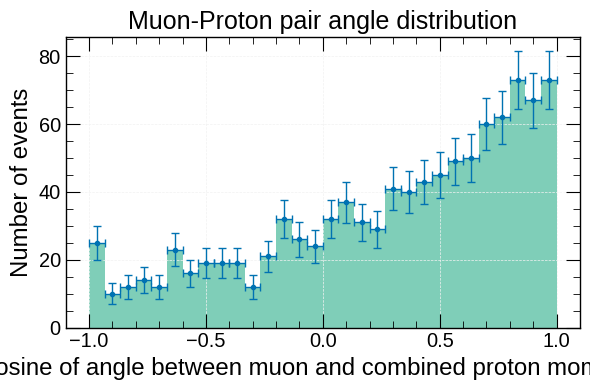

In [48]:
# Repeat everything above but for reco
#---------------------------- Merge leading proton, recoil proton, and muon momentum dataframes ----------------------------
# Get rank 1 and rank 2 proton momenta per event, merged on event_number
# so we only keep events that have BOTH a rank 1 and rank 2 proton
rank1_reco = df.loc[df["reco_proton_rank"] == 1, ["event_number", "reco_pmag", "reco_px", "reco_py", "reco_pz"]]
rank2_reco = df.loc[df["reco_proton_rank"] == 2, ["event_number", "reco_pmag", "reco_px", "reco_py", "reco_pz"]]
muon_reco = df.loc[abs(df["reco_pdg"]) == 13, ["event_number", "reco_pmag", "reco_px", "reco_py", "reco_pz", "reco_pdg"]]

muon_reco = muon_reco.rename(columns={
    "reco_pmag": "reco_pmag_muon",
    "reco_px": "reco_px_muon",
    "reco_py": "reco_py_muon",
    "reco_pz": "reco_pz_muon",
})

merged_reco = pd.merge(rank1_reco, rank2_reco, on="event_number", suffixes=("_rank1", "_rank2"))
merged_reco = pd.merge(merged_reco, muon_reco, on="event_number")

# Check
#print(merged_reco.head(10))

print(f"Number of events with >=2 protons: {len(merged_reco)}")

#---------------------------- Leading vs. recoil proton momenta ----------------------------
plt.figure(figsize=(6, 6))
plt.scatter(merged_reco["reco_pmag_rank1"], merged_reco["reco_pmag_rank2"], s=10, alpha=0.5)
plt.xlabel("Leading proton momentum [GeV/c]")
plt.ylabel("Recoil proton momentum [GeV/c]")
plt.title("Leading vs. Recoil proton momentum per event", fontsize=18)

# Optional: force equal aspect and draw the y=x line, since rank2 <= rank1 always
#max_p = max(merged_reco["reco_pmag_rank1"].max(), merged_reco["reco_pmag_rank2"].max())
max_p = 4
plt.plot([0, max_p], [0, max_p], color="gray", linestyle="--", linewidth=1, label="y = x")
plt.xlim(0, max_p)
plt.ylim(0, max_p)
plt.gca().set_aspect("equal")
plt.legend()
plt.tight_layout()
plt.show()

#---------------------------- Leading and recoil proton momenta separate histograms with stat errors ----------------------------
nbins_reco_pmag = 30
hist_reco_pmag, bin_edges_reco_pmag = np.histogram(merged_reco["reco_pmag_rank1"], bins=nbins_reco_pmag, range=(0, 6))
bin_centers_reco_pmag = (bin_edges_reco_pmag[:-1] + bin_edges_reco_pmag[1:])/2
bin_width_reco_pmag = (bin_edges_reco_pmag[-1] + bin_edges_reco_pmag[0])/nbins_reco_pmag
labels_reco_pmag = np.arange(0, nbins_reco_pmag) 

hist_reco_pmag_rank2, bin_edges_reco_pmag_rank2 = np.histogram(merged_reco["reco_pmag_rank2"], bins=nbins_reco_pmag, range=(0, 6))
bin_centers_reco_pmag_rank2 = (bin_edges_reco_pmag_rank2[:-1] + bin_edges_reco_pmag_rank2[1:])/2
bin_width_reco_pmag_rank2 = (bin_edges_reco_pmag_rank2[-1] + bin_edges_reco_pmag_rank2[0])/nbins_reco_pmag

# Can do np.hist to get x and y values, then plot those as a step/scatter function with error bars
#plt.hist(merged_reco["reco_pmag_rank1"], bins=30, alpha=0.5, label="Leading proton")
#plt.hist(merged_reco["reco_pmag_rank2"], bins=30, alpha=0.5, label="Recoil proton")
plt.errorbar(bin_centers_reco_pmag, hist_reco_pmag, xerr=bin_width_reco_pmag/2, yerr=np.sqrt(hist_reco_pmag), fmt='.', label='Leading proton', elinewidth=1, capsize=3)
plt.errorbar(bin_centers_reco_pmag_rank2, hist_reco_pmag_rank2, xerr=bin_width_reco_pmag_rank2/2, yerr=np.sqrt(hist_reco_pmag_rank2), fmt='.', label='Recoil proton', elinewidth=1, capsize=3)
plt.stairs(hist_reco_pmag, bin_edges_reco_pmag, fill=True, color='#0072B2', alpha=0.5, edgecolor='black')
plt.stairs(hist_reco_pmag_rank2, bin_edges_reco_pmag_rank2, fill=True, color='#D55E00', alpha=0.5, edgecolor='black')
plt.xlabel("Proton momentum [GeV/c]")
plt.ylabel("Number of events")
plt.title("Leading and Recoil proton momentum distributions", fontsize=18)
plt.legend()
plt.tight_layout()
plt.show()

#---------------------------- Muon-Proton pair angle ----------------------------
muon_proton_angles = []

for index, row in merged_reco.iterrows():
    proton1 = [row["reco_px_rank1"], row["reco_py_rank1"], row["reco_pz_rank1"]]
    proton2 = [row["reco_px_rank2"], row["reco_py_rank2"], row["reco_pz_rank2"]]
    muon = [row["reco_px_muon"], row["reco_py_muon"], row["reco_pz_muon"]]

    combined_protons = vector_sum(proton1, proton2)
    angle = theta(combined_protons, muon)
    muon_proton_angles.append(angle)


nbins_muon_proton = 30
hist_muon_proton_reco, bin_edges_muon_proton_reco = np.histogram(muon_proton_angles, bins=nbins_muon_proton, range=(-1, 1))
bin_centers_muon_proton = (bin_edges_muon_proton_reco[:-1] + bin_edges_muon_proton_reco[1:])/2
bin_width_muon_proton = (bin_edges_muon_proton_reco[-1] - bin_edges_muon_proton_reco[0]) / nbins_muon_proton
labels_muon_proton = np.arange(0, nbins_muon_proton)

plt.figure(figsize=(6, 4))
plt.errorbar(bin_centers_muon_proton, hist_muon_proton_reco, xerr=bin_width_muon_proton/2, yerr=np.sqrt(hist_muon_proton_reco), fmt='.', label='Muon-Proton pair angle', elinewidth=1, capsize=3)
plt.stairs(hist_muon_proton_reco, bin_edges_muon_proton_reco, fill=True, color='#009E73', alpha=0.5, edgecolor='black')
plt.xlabel("Cosine of angle between muon and combined proton momentum")
plt.ylabel("Number of events")
plt.title("Muon-Proton pair angle distribution", fontsize=18)
plt.grid(color='0.95')
plt.tight_layout()
plt.show()


## Kinematics True vs. Reco

   event_number  true_pmag_rank1  true_px_rank1  true_py_rank1  true_pz_rank1  \
0             4         0.590912       0.310534       0.247582       0.437548   
1             6         0.786369       0.716522       0.322068       0.035276   
2             8         0.699587       0.039846       0.285611       0.637386   
3            11         0.373143       0.002180      -0.177929       0.327982   
4            14         0.536654       0.176068       0.506525       0.020754   
5            16         0.607322      -0.470298       0.185579       0.336483   
6            20         1.831453       0.077334      -0.177885       1.821153   
7            22         1.162880       0.214417      -0.127244       1.135836   
8            22         1.162880       0.214417      -0.127244       1.135836   
9            31         0.590854      -0.516544       0.096871       0.270013   

   true_pmag_rank2  true_px_rank2  true_py_rank2  true_pz_rank2  \
0         0.436133      -0.057161      -0

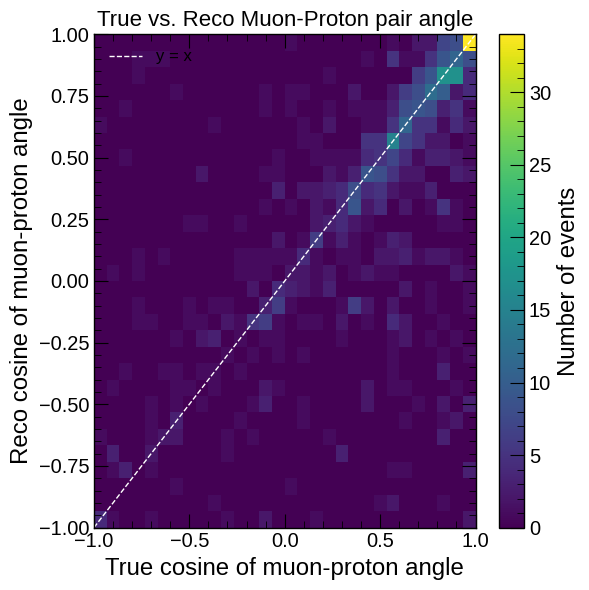

In [51]:
# Compare the true vs. reco values for leading proton momentum, recoil proton momentum, and muon-proton pair angle
# 2D histograms with 1D projections for each variable

# First merge the true and reco dataframes on event_number to get only events that have both true and reco values
merged_true_reco = pd.merge(merged_true, merged_reco, on="event_number")

print(merged_true_reco.head(10))

#---------------------------- Muon-Proton pair angle (true), tracked by event ----------------------------
muon_proton_angles_true = []
event_numbers_true = []

for index, row in merged_true.iterrows():
    proton1 = [row["true_px_rank1"], row["true_py_rank1"], row["true_pz_rank1"]]
    proton2 = [row["true_px_rank2"], row["true_py_rank2"], row["true_pz_rank2"]]
    muon = [row["true_px_muon"], row["true_py_muon"], row["true_pz_muon"]]

    combined_protons = vector_sum(proton1, proton2)
    angle = theta(combined_protons, muon)
    muon_proton_angles_true.append(angle)
    event_numbers_true.append(row["event_number"])

angle_df_true = pd.DataFrame({
    "event_number": event_numbers_true,
    "angle_true": muon_proton_angles_true,
})

#---------------------------- Muon-Proton pair angle (reco), tracked by event ----------------------------
muon_proton_angles_reco = []
event_numbers_reco = []

for index, row in merged_reco.iterrows():
    proton1 = [row["reco_px_rank1"], row["reco_py_rank1"], row["reco_pz_rank1"]]
    proton2 = [row["reco_px_rank2"], row["reco_py_rank2"], row["reco_pz_rank2"]]
    muon = [row["reco_px_muon"], row["reco_py_muon"], row["reco_pz_muon"]]

    combined_protons = vector_sum(proton1, proton2)
    angle = theta(combined_protons, muon)
    muon_proton_angles_reco.append(angle)
    event_numbers_reco.append(row["event_number"])

angle_df_reco = pd.DataFrame({
    "event_number": event_numbers_reco,
    "angle_reco": muon_proton_angles_reco,
})

#---------------------------- Merge true and reco angles on event_number ----------------------------
angle_comparison = pd.merge(angle_df_true, angle_df_reco, on="event_number")

print(f"Number of events with both true and reco angle: {len(angle_comparison)}")

#---------------------------- 2D histogram: true vs. reco angle ----------------------------
plt.figure(figsize=(6, 6))

h = plt.hist2d(
    angle_comparison["angle_true"],
    angle_comparison["angle_reco"],
    bins=30,
    range=[[-1, 1], [-1, 1]],
    cmap="viridis",
)

plt.colorbar(h[3], label="Number of events")
plt.plot([-1, 1], [-1, 1], color="white", linestyle="--", linewidth=1, label="y = x")
plt.xlabel("True cosine of muon-proton angle")
plt.ylabel("Reco cosine of muon-proton angle")
plt.title("True vs. Reco Muon-Proton pair angle", fontsize=16)
plt.legend()
plt.tight_layout()
plt.show()

## Systematic Errors

Just plot the genie error weights per event?

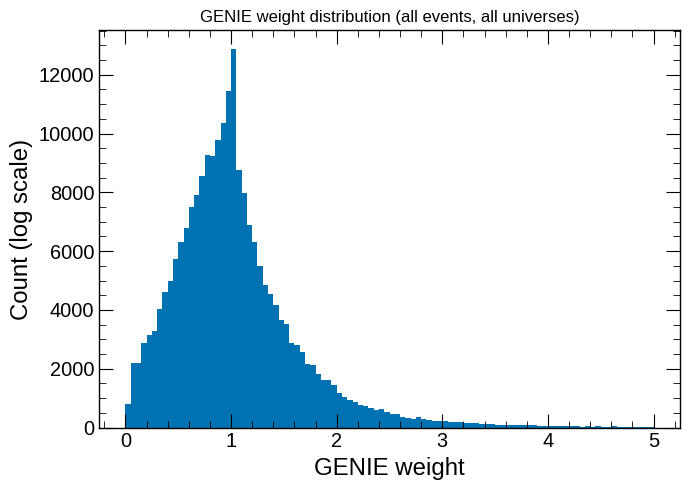

In [ ]:
genie_weights = tree["genie_weights"].array(library="ak") 
ev1_wgts = genie_weights[0] # Weights for the first event (all universes)
# Flatten across all events/universes into one 1D array
flat_weights = ak.to_numpy(ak.flatten(genie_weights))

plt.figure(figsize=(7, 5))
plt.hist(flat_weights, bins=100, range=(0, 5), edgecolor="none")
#plt.yscale("log")
plt.xlabel("GENIE weight")
plt.ylabel("Count (log scale)")
plt.title("GENIE weight distribution (all events, all universes)", fontsize=12)
plt.tight_layout()
plt.show()

## Single Bin Cross Section

$\sigma = \frac{N_{obs}-N_{background} }{N_{target} \Phi \epsilon}$ <br>
Number of observed candidate events <br>
Number of estimated background events <br>
Number of target nuclei in the active volume of the detector <br>
Integrated neutrino flux <br>
Detector selection efficiency <br>

In [ ]:
# Number of observed candidate events = number of reco events
# Number of background events = number of reco events that are not true signal events
# Number of target nuclei in the active volume
# Integrated neutrino flux
# Detector selection efficiency (efficiency calculated above)

# Try this with the 3 hours of sandbox data

n_obs = sum(signal_event)  # Number of observed candidate events (This will be data only)
n_bg = sum(signal_event) - sum(true_signal_event)  # Number of background events (This will be monte carlo)
n_t = 1 # Number of target nuclei in the active volume (placeholder value, replace with actual number)
phi = 1 # cm^-2 Integrated neutrino flux (placeholder value, replace with actual flux)
eff = efficiency  # Detector selection efficiency (calculated above)

# Number of target nuclei in the active volume calculation
#n_t = volume * density * avogadro_number / molar_mass 
# Do we use containment cut or full tpc volume for the volume?
vol = 2 * (63.931 - 8) * 2 * (62.076 - 8) * 2 * (64.3163 - 8) #volume of tpc in cm^3, subtracting 8 cm from each side for containment cut
n_avo = 6.022e23 #avogadro's number
density = 1.4 #g/cm^3 for liquid argon approximately
molar_mass = 39.948 #g/mol for liquid argon
n_t = vol * density * n_avo / molar_mass # Number of target nuclei in the active volume

# Integrated flux calculation
flux_file = uproot.open("/global/homes/z/zaemoore/numiFluxSystFull.root")

def get_flux_hist(species, mode="rhc", corrected=True):
    """species: 'numu', 'numubar', 'nue', 'nuebar'"""
    tag = "ppfx_corrected" if corrected else "nominal"
    name = f"hflux_{mode}_{species}_{tag}"
    h = flux_file[name]
    values = h.values()          # per-bin flux content (array, len = n_bins)
    edges  = h.axis().edges()    # bin edges in true neutrino energy [GeV]
    return values, edges

def integrated_flux_shape(species_list, mode="rhc", e_lo=None, e_hi=None):
    """
    Sum the flux histograms for one or more species over an energy range.
    e_lo/e_hi in GeV; leave as None to integrate the full spectrum.
    Returns the integral in whatever units the file's bin content is in
    """
    total = 0.0
    for species in species_list:
        values, edges = get_flux_hist(species, mode=mode)
        lo_idx = 0 if e_lo is None else np.searchsorted(edges, e_lo)
        hi_idx = len(values) if e_hi is None else np.searchsorted(edges, e_hi)
        total += values[lo_idx:hi_idx].sum()
    return total

flux_shape = integrated_flux_shape(["numu", "numubar"])

# --- Apply your POT normalization ---
mc_POT = 1e19          # POT of flux file
run1_POT      = 1.1E19        # POT of run 1

# This is ONLY MC, so it makes sense to only multiply by the mc_POT
phi = flux_shape * mc_POT# Integrated neutrino flux in cm^-2

print(f"Integrated flux (phi):      {phi:.6e}  nu/cm^2")
print(n_t)
print(eff)
xsec = (n_obs - n_bg) / (n_t * phi * eff)  # Cross-section calculation
print("Single bin cross section: ", xsec)
#10e-38 order makes sense

Integrated flux (phi):      5.637004e+15  nu/cm^2
2.875775569995823e+28
0.5307692307692308
Single bin cross section:  1.603873081397849e-42
